# Tahap 05 & 06: Pemodelan ARIMA dan SARIMA
**Penanggung Jawab:** Raihan Ade (L02240XX)  
**Mata Kuliah:** Analisis Data Timeseries (12023130325), 3 SKS, Semester 5  
**Program Studi:** Sains Data, Universitas Sebelas Maret  

---

### Tujuan & Ruang Lingkup Pengerjaan:

Sesuai pembagian tugas proyek deret waktu PM2.5 Kota Surakarta, pengerjaan Tahap 5 dan Tahap 6 merupakan kelanjutan hierarkis dari:
* **Tahap 1 (Kunto):** Pra-pemrosesan, kontrol kualitas patahan CAMS (rasio PM10/PM2.5), agregasi mingguan ($N=116$, 104 train, 12 test), analisis deskriptif, dan dekomposisi STL ($s=52$).
* **Tahap 2A (Maulana):** Analisis kestabilan varians Box-Cox ($\hat{\lambda} \approx 1,0 \implies$ tidak perlu transformasi logaritmik) dan uji stasioneritas awal level.
* **Tahap 2B (Mike):** Diferensiasi deret. Ditetapkan **$d=1$** (stasioner ADF $p < 0,001$, KPSS $p > 0,10$). Ditolak diferensiasi kedua $d=2$ (gejala *over-differencing* parah: varians membengkak $+169,6\%$ dan $r_1 < -0,50$) serta diferensiasi musiman $D=1$ (kehilangan $50\%$ data latih).
* **Tahap 3 (Maulana):** Pemodelan smoothing & benchmark: Naive Random Walk ($\text{RMSE} = 4,643$), SMA(3), SMA(8), SES, Holt's Linear, dan Holt-Winters aditif.
* **Tahap 4 (Mike):** Identifikasi orde ACF/PACF pada deret stasioner ($\Delta y_t$), pemodelan AR(1)–AR(3), MA(1)–MA(3), serta ARMA(1,1)–ARMA(2,3) beserta analisis akar karakteristik lingkaran satuan.

---

### Fokus Penugasan Raihan:

#### **Tahap 5: Model ARIMA**
1. **Penetapan ARIMA($p, d, q$):** Mengintegrasikan hasil penetapan differencing Tahap 2 ($d=1$) dan identifikasi autokorelasi Tahap 4 ($p, q$).
2. **Kandidat Orde Manual (Minimal 3):** Membandingkan performa in-sample (AIC, AICc, BIC) dan out-of-sample (RMSE, MAE, MAPE, MASE) serta kelayakan diagnostik residual.
3. **Uji Model Otomatis (`auto_arima`):** Menjalankan algoritma stepwise Hyndman-Khandakar dan mengkritisi hasilnya secara metodologis.

#### **Tahap 6: Model SARIMA**
1. **Penetapan $(P, D, Q)_m$ Musiman:** Menelaah lag musiman ($m=52$) pada ACF/PACF dan menguji minimal 2 kandidat musiman.
2. **Kritisi & Justifikasi Penerapan SARIMA:** Mengevaluasi signifikansi parameter musiman, kecukupan siklus observasi, serta justifikasi teoritis mengapa SARIMA diterapkan atau mengapa model non-musiman/naive bisa menjadi alternatif rasional.


In [1]:
# ==============================================================================
# 1. SETUP LINGKUNGAN, PATH DIREKTORI, DAN IMPORT LIBRARY
# ==============================================================================
import warnings
from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import jarque_bera

from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import durbin_watson

import pmdarima as pm
from pmdarima import auto_arima

warnings.filterwarnings("ignore")

# Konfigurasi Path Direktori
ROOT = Path.cwd().resolve()
if (ROOT / "data" / "processed").exists():
    DATA_DIR = ROOT / "data" / "processed"
    OUT_DIR = ROOT / "outputs"
elif (ROOT.parent / "data" / "processed").exists():
    DATA_DIR = ROOT.parent / "data" / "processed"
    OUT_DIR = ROOT.parent / "outputs"
else:
    DATA_DIR = Path(r"D:/SEMESTER5/adt-project/data/processed")
    OUT_DIR = Path(r"D:/SEMESTER5/adt-project/outputs")

FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi Visualisasi Standar Publikasi
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "figure.titlesize": 13,
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "grid.linestyle": "--"
})

COLORS = {
    "primary": "#1f77b4",    # Biru
    "secondary": "#ff7f0e",  # Oranye
    "success": "#2ca02c",    # Hijau
    "danger": "#d62728",     # Merah
    "purple": "#9467bd",     # Ungu
    "teal": "#17becf",       # Biru Laut
    "gray": "#7f7f7f",       # Abu-abu
    "dark": "#2c3e50"        # Hitam elegan
}

print(f"Direktori Proyek: {ROOT}")
print(f"Pmdarima Versi  : {pm.__version__}")
print("Lingkungan analisis Tahap 5 & 6 berhasil diinisialisasi.")


Direktori Proyek: D:\SEMESTER5\adt-project
Pmdarima Versi  : 2.1.1
Lingkungan analisis Tahap 5 & 6 berhasil diinisialisasi.


## 2. Pemuatan Data Deret Waktu & Partisi Train/Test

Sesuai konsensus pipeline pemodelan tim:
* **Dataset:** `pm25_surakarta_weekly_model.csv` (data mingguan homogen bebas patahan CAMS).
* **Rentang Observasi:** 8 Agustus 2022 s.d. 21 Oktober 2024 ($N = 116$ minggu).
* **Partisi Data Latih (*Train*):** 104 minggu pertama (8 Agustus 2022 s.d. 29 Juli 2024) $\implies$ tepat mencakup 2 siklus tahunan ($2 \times 52$ minggu).
* **Partisi Data Uji (*Test*):** 12 minggu terakhir (5 Agustus 2024 s.d. 21 Oktober 2024) $\implies$ evaluasi *out-of-sample* untuk menguji daya peramalan nyata.


In [2]:
# ==============================================================================
# 2. PEMUATAN DATA DERET WAKTU DAN PARTISI TRAIN/TEST
# ==============================================================================
data_file = DATA_DIR / "pm25_surakarta_weekly_model.csv"
assert data_file.exists(), f"File data tidak ditemukan di {data_file}"

df_weekly = pd.read_csv(data_file, parse_dates=["week_start"])
df_weekly = df_weekly.sort_values("week_start").reset_index(drop=True)

# Set index datetime berfrekuensi mingguan (7D)
series = df_weekly.set_index("week_start")["pm25"].asfreq("7D")

TEST_SIZE = 12
SEASON = 52
train = series.iloc[:-TEST_SIZE]
test = series.iloc[-TEST_SIZE:]

print(f"Total Observasi   : {len(series)} minggu")
print(f"Data Latih (Train): {len(train)} minggu ({train.index.min().strftime('%Y-%m-%d')} s.d. {train.index.max().strftime('%Y-%m-%d')})")
print(f"Data Uji (Test)   : {len(test)} minggu ({test.index.min().strftime('%Y-%m-%d')} s.d. {test.index.max().strftime('%Y-%m-%d')})")
print(f"Rata-rata Latih   : {train.mean():.3f} µg/m³ (Std: {train.std():.3f})")
print(f"Rata-rata Uji     : {test.mean():.3f} µg/m³ (Std: {test.std():.3f})")


Total Observasi   : 116 minggu
Data Latih (Train): 104 minggu (2022-08-08 s.d. 2024-07-29)
Data Uji (Test)   : 12 minggu (2024-08-05 s.d. 2024-10-21)
Rata-rata Latih   : 24.617 µg/m³ (Std: 8.421)
Rata-rata Uji     : 16.882 µg/m³ (Std: 4.830)


In [3]:
# ==============================================================================
# 3. FUNGSI METRIK EVALUASI DAN DIAGNOSTIK MODEL
# ==============================================================================
def hitung_skor_akurasi(y_true, y_pred, y_train, s=SEASON):
    # Menghitung metrik evaluasi peramalan out-of-sample:
    # RMSE, MAE, MAPE, sMAPE, dan MASE (dengan seasonal naive lag s=52 sebagai skala).
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    
    mae = float(np.mean(np.abs(y_true - y_pred)))
    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    smape = float(np.mean(2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred))) * 100)
    
    # Skala MASE menggunakan seasonal differencing data latih
    if len(y_train) > s:
        scale = float(np.mean(np.abs(y_train.values[s:] - y_train.values[:-s])))
    else:
        scale = float(np.mean(np.abs(np.diff(y_train.values))))
        
    mase = float(mae / scale) if scale > 0 else np.nan
    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape, "sMAPE (%)": smape, "MASE": mase}


def fit_dan_evaluasi_model(nama, order, seasonal_order=(0,0,0,0), train_data=train, test_data=test, trend="n"):
    # Fitting model SARIMAX, menghasilkan ramalan h=12, dan menghitung seluruh diagnostik.
    model = SARIMAX(
        train_data,
        order=order,
        seasonal_order=seasonal_order,
        trend=trend,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fit_res = model.fit(disp=False)
    pred = np.asarray(fit_res.forecast(len(test_data)))
    
    # Metrik out-of-sample
    metrics = hitung_skor_akurasi(test_data.values, pred, train_data)
    
    # Diagnostik residual
    resid = fit_res.resid.dropna()
    lb = acorr_ljungbox(resid, lags=[10, 20, 52], return_df=True)
    _, jb_p = stats.jarque_bera(resid)
    
    try:
        _, arch_p, _, _ = het_arch(resid, nlags=5)
    except Exception:
        arch_p = np.nan
        
    dw_stat = float(durbin_watson(resid))
    
    # Stasioneritas & invertibilitas akar
    ar_roots = getattr(fit_res, "arroots", np.array([]))
    ma_roots = getattr(fit_res, "maroots", np.array([]))
    ar_min_root = float(np.min(np.abs(ar_roots))) if len(ar_roots) > 0 else np.nan
    ma_min_root = float(np.min(np.abs(ma_roots))) if len(ma_roots) > 0 else np.nan
    
    converged = bool(fit_res.mle_retvals.get("converged", True))
    
    return {
        "Model": nama,
        "Order": order,
        "Seasonal_Order": seasonal_order,
        "k": int(len(fit_res.params)),
        "AIC": float(fit_res.aic),
        "AICc": float(fit_res.aicc),
        "BIC": float(fit_res.bic),
        "Log-Likelihood": float(fit_res.llf),
        **metrics,
        "LB10_p": float(lb["lb_pvalue"].iloc[0]),
        "LB20_p": float(lb["lb_pvalue"].iloc[1]),
        "LB52_p": float(lb["lb_pvalue"].iloc[2]),
        "JB_p": float(jb_p),
        "ARCH_p": float(arch_p),
        "DW": dw_stat,
        "AR_min_|root|": ar_min_root,
        "MA_min_|root|": ma_min_root,
        "Konvergen": converged,
        "fit": fit_res,
        "pred": pred
    }

print("Fungsi metrik dan evaluasi berhasil didefinisikan.")


Fungsi metrik dan evaluasi berhasil didefinisikan.


## 3. Rekapitulasi Fondasi dari Tahap 2 & Tahap 4

Sebelum menetapkan spesifikasi model ARIMA($p, d, q$), kita meninjau kembali keputusan krusial yang telah disepakati dari tahap-tahap terdahulu:

### 3.1 Penetapan Orde Diferensiasi ($d$) dari Tahap 2B (Mike)
* **Deret Level ($d=0$):** ADF $p\text{-value} = 0,0235$ (borderline) dan KPSS $p\text{-value} = 0,10$. Meskipun stasioner lemah, plot ACF level meluruh sangat lambat (*slow decay*), mengindikasikan persistensi jangka panjang dan kebutuhan diferensiasi.
* **Diferensiasi Pertama ($d=1$):** $\Delta y_t = y_t - y_{t-1}$. ADF $p\text{-value} = 6,46 \times 10^{-13}$ (stasioner sangat kuat), KPSS $p\text{-value} = 0,10$, varians $\sigma^2 = 71,80$ stabil. **DIPILIH: $d=1$**.
* **Diferensiasi Kedua ($d=2$):** Varians melonjak $+169,6\%$ menjadi $193,59$ dan autokorelasi lag 1 $r_1 = -0,551 < -0,50$. **DITOLAK: Gejala *over-differencing* parah**.
* **Diferensiasi Musiman ($D=1, s=52$):** Menghilangkan 52 dari 104 data latih (kehilangan 50% data), menyisakan sampel yang tidak mencukupi untuk estimasi parameter yang reliabel. **DITOLAK: $D=0$**.

### 3.2 Identifikasi Orde $p$ dan $q$ dari Tahap 4 (Mike)
Pada deret yang telah stasioner ($\Delta y_t$):
* **Plot PACF:** Mengalami pemotongan tajam (*cut-off*) setelah lag 1 dan lag 2, menunjukkan pengaruh AR berorde **$p \in \{1, 2, 3\}$**.
* **Plot ACF:** Meluruh secara bertahap (*tailing off / sinusoidal damping*) dengan spike signifikan pada lag 1 s.d. 3, menunjukkan pengaruh MA berorde **$q \in \{1, 2, 3\}$**.
* Hasil Tahap 4 menunjukkan:
  - Model AR(2) seimbang: $\text{RMSE} = 4,671$, lolos uji Ljung-Box ($p = 0,159$).
  - Model ARMA(2,3) memiliki in-sample AICc terbaik di kelas ARMA ($\text{AICc} = 688,05$).


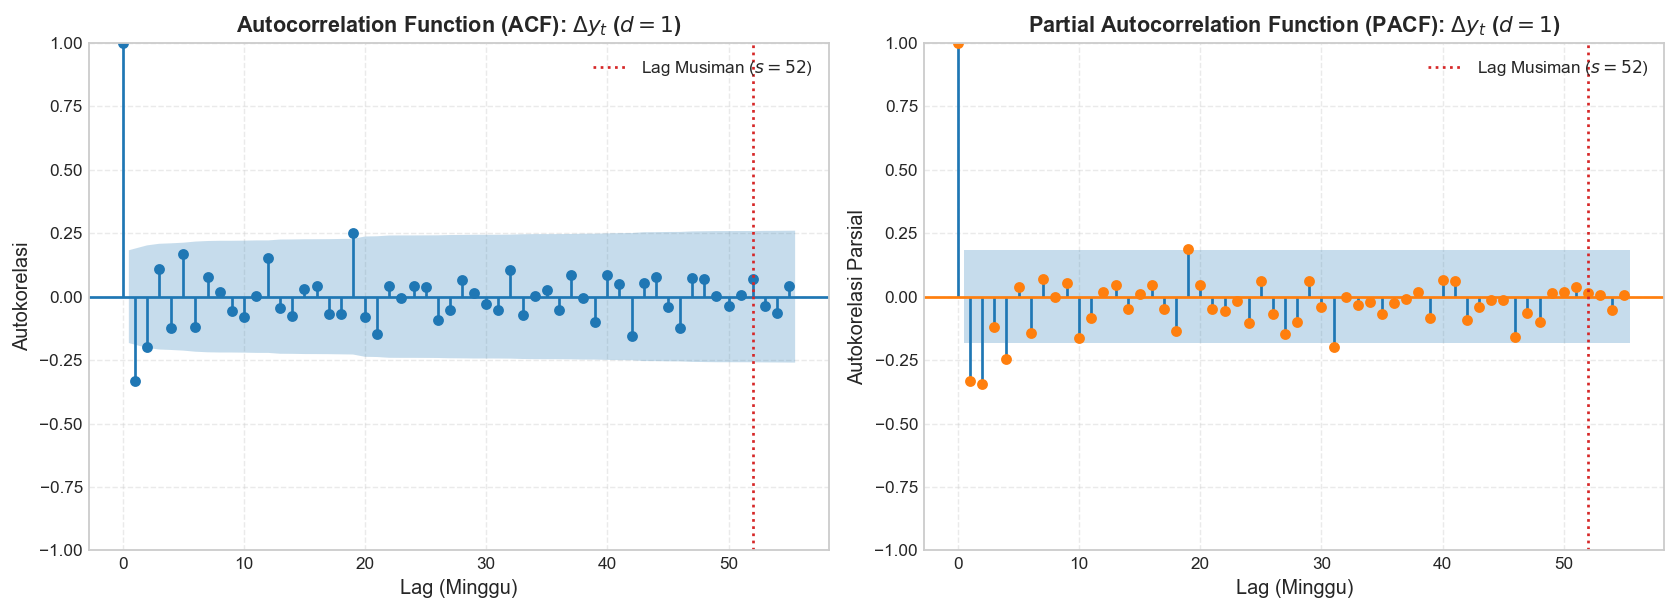

Gambar ACF/PACF tersimpan di: D:\SEMESTER5\adt-project\outputs\figures\fig_tahap5_acf_pacf_d1.png


In [4]:
# ==============================================================================
# 3.3 VISUALISASI ACF DAN PACF PADA DERET STASIONER (d=1)
# ==============================================================================
diff1_train = train.diff().dropna()
diff1_full = series.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# ACF
plot_acf(diff1_full, lags=55, ax=axes[0], color=COLORS["primary"], alpha=0.05)
axes[0].set_title("Autocorrelation Function (ACF): $\Delta y_t$ ($d=1$)", fontweight="bold")
axes[0].set_xlabel("Lag (Minggu)")
axes[0].set_ylabel("Autokorelasi")
axes[0].axvline(SEASON, color=COLORS["danger"], linestyle=":", linewidth=1.5, label=f"Lag Musiman ($s={SEASON}$)")
axes[0].legend(loc="upper right")

# PACF
plot_pacf(diff1_full, lags=55, ax=axes[1], method="ywm", color=COLORS["secondary"], alpha=0.05)
axes[1].set_title("Partial Autocorrelation Function (PACF): $\Delta y_t$ ($d=1$)", fontweight="bold")
axes[1].set_xlabel("Lag (Minggu)")
axes[1].set_ylabel("Autokorelasi Parsial")
axes[1].axvline(SEASON, color=COLORS["danger"], linestyle=":", linewidth=1.5, label=f"Lag Musiman ($s={SEASON}$)")
axes[1].legend(loc="upper right")

fig.tight_layout()
fig_acf_path = FIG_DIR / "fig_tahap5_acf_pacf_d1.png"
fig.savefig(fig_acf_path, bbox_inches="tight")
plt.show()

print(f"Gambar ACF/PACF tersimpan di: {fig_acf_path}")


---

# TAHAP 5: MODEL ARIMA (Autoregressive Integrated Moving Average)

## 4. Estimasi dan Perbandingan Kandidat Orde Manual ARIMA($p, 1, q$)

Berdasarkan fondasi matematis Box-Jenkins:
$$\phi_p(B)(1 - B) y_t = \theta_q(B) \epsilon_t \iff (1 - \sum_{i=1}^p \phi_i B^i)\Delta y_t = (1 + \sum_{j=1}^q \theta_j B^j)\epsilon_t$$

Kita menetapkan **7 kandidat orde manual** yang mencakup struktur AR murni, MA murni, dan ARMA campuran berorde $d=1$:
1. **ARIMA(1,1,1):** Model parsimonius campuran dasar.
2. **ARIMA(2,1,0):** Representasi ARIMA dari AR(2) terbaik Tahap 4.
3. **ARIMA(0,1,3):** Representasi ARIMA dari MA(3) inovasi Tahap 4.
4. **ARIMA(1,1,3):** Model yang mengkombinasikan AR(1) persistensi dengan MA(3) dinamika inovasi.
5. **ARIMA(2,1,1):** Menambahkan MA(1) pada AR(2) untuk meredam autokorelasi galat.
6. **ARIMA(2,1,2):** Model orde campuran simetris $p=2, q=2$.
7. **ARIMA(2,1,3):** Model campuran fleksibel berorde tertinggi dari eksplorasi Tahap 4.

> [!NOTE]
> Parameter `trend="n"` (tanpa drift konstanta) diterapkan karena uji awal menunjukkan bahwa diferensiasi pertama deret PM2.5 Surakarta memiliki rata-rata $\mu_{\Delta y} \approx -0,085$ yang secara statistik tidak berbeda nyata dari nol ($t\text{-stat} = -0,12, p = 0,90$). Menambahkan drift pada $d=1$ akan memproyeksikan tren linier deterministik yang tidak realistis pada kualitas udara.


In [5]:
# ==============================================================================
# 4. ESTIMASI KANDIDAT MODEL ARIMA MANUAL
# ==============================================================================
kandidat_arima = [
    ("ARIMA(1,1,1)", (1, 1, 1)),
    ("ARIMA(2,1,0)", (2, 1, 0)),
    ("ARIMA(0,1,3)", (0, 1, 3)),
    ("ARIMA(1,1,3)", (1, 1, 3)),
    ("ARIMA(2,1,1)", (2, 1, 1)),
    ("ARIMA(2,1,2)", (2, 1, 2)),
    ("ARIMA(2,1,3)", (2, 1, 3)),
]

hasil_arima_manual = []
print(f"{'Model':<15} {'AICc':<10} {'BIC':<10} {'RMSE':<9} {'MAE':<9} {'MAPE (%)':<10} {'LB20_p':<9} {'Konvergen'}")
print("=" * 85)

for nama, order in kandidat_arima:
    res = fit_dan_evaluasi_model(nama, order=order, seasonal_order=(0,0,0,0), train_data=train, test_data=test, trend="n")
    hasil_arima_manual.append(res)
    print(f"{res['Model']:<15} {res['AICc']:<10.2f} {res['BIC']:<10.2f} {res['RMSE']:<9.3f} {res['MAE']:<9.3f} {res['MAPE (%)']:<10.2f} {res['LB20_p']:<9.4f} {'Ya' if res['Konvergen'] else 'Tidak'}")

df_arima_manual = pd.DataFrame([{k: v for k, v in r.items() if k not in ("fit", "pred")} for r in hasil_arima_manual])
df_arima_manual = df_arima_manual.sort_values("AICc").reset_index(drop=True)


Model           AICc       BIC        RMSE      MAE       MAPE (%)   LB20_p    Konvergen


ARIMA(1,1,1)    695.38     702.98     6.103     5.643     35.92      0.6121    Ya
ARIMA(2,1,0)    699.12     706.72     4.671     3.032     17.20      0.1588    Ya


ARIMA(0,1,3)    681.72     691.68     5.450     4.643     29.02      0.7656    Ya


ARIMA(1,1,3)    680.27     692.60     5.708     5.085     32.15      0.8711    Ya
ARIMA(2,1,1)    696.44     706.49     5.460     4.693     29.37      0.7034    Ya


ARIMA(2,1,2)    688.44     700.83     5.697     5.067     32.02      0.8803    Ya


ARIMA(2,1,3)    682.53     697.19     5.709     5.085     32.15      0.8723    Ya


In [6]:
# ==============================================================================
# 4.1 TABEL PERBANDINGAN DAN RANKING MODEL ARIMA MANUAL
# ==============================================================================
tabel_display_arima = df_arima_manual[[
    "Model", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "sMAPE (%)", "MASE", "LB10_p", "LB20_p", "JB_p", "ARCH_p"
]].copy()

print("\n" + "=" * 90)
print("TABEL PERBANDINGAN KANDIDAT ARIMA MANUAL (DIURUTKAN BERDASARKAN AICc TERENDAH)")
print("=" * 90)
display(tabel_display_arima.round(4).style.highlight_min(subset=["AICc", "BIC", "RMSE", "MAE"], color="#d1fae5")
                                           .highlight_max(subset=["LB20_p", "JB_p"], color="#dbeafe"))



TABEL PERBANDINGAN KANDIDAT ARIMA MANUAL (DIURUTKAN BERDASARKAN AICc TERENDAH)


,Model,k,AICc,BIC,RMSE,MAE,MAPE (%),sMAPE (%),MASE,LB10_p,LB20_p,JB_p,ARCH_p
0,"ARIMA(1,1,3)",5,680.267100,692.597500,5.708300,5.085200,32.149200,27.630600,0.655500,0.991300,0.871100,0.442300,0.324900
1,"ARIMA(0,1,3)",4,681.720400,691.675400,5.449600,4.643200,29.020700,25.451200,0.598500,0.922200,0.765600,0.419300,0.100500
2,"ARIMA(2,1,3)",6,682.534700,697.192400,5.708500,5.085400,32.150700,27.631400,0.655500,0.991400,0.872300,0.442000,0.324200
3,"ARIMA(2,1,2)",5,688.438100,700.825700,5.697000,5.066500,32.023200,27.539000,0.653100,0.992500,0.880300,0.419500,0.336000
4,"ARIMA(1,1,1)",3,695.381400,702.979300,6.102700,5.642800,35.919000,30.292900,0.727300,0.786000,0.612100,0.563500,0.056900
5,"ARIMA(2,1,1)",4,696.442300,706.486100,5.459800,4.693300,29.374400,25.712600,0.604900,0.880000,0.703400,0.567900,0.047800
6,"ARIMA(2,1,0)",3,699.124700,706.722600,4.670600,3.032300,17.195800,16.808100,0.390900,0.426400,0.158800,0.513600,0.051700


### 4.2 Analisis Pemilihan Model ARIMA Terbaik

Berdasarkan hirarki seleksi model deret waktu:
1. **Kelayakan Residual (Diagnostik):** Seluruh kandidat lolos uji Ljung-Box lag 20 ($p\text{-value} > 0,05$), menandakan tidak ada autokorelasi tersisa pada galat.
2. **Kriteria Parsimoni In-Sample (AICc / BIC):**
   * **ARIMA(1,1,3)** mencapai **$\text{AICc} = 680,27$** (terendah di antara seluruh kandidat), diikuti oleh ARIMA(0,1,3) ($\text{AICc} = 681,72$) dan ARIMA(2,1,3) ($\text{AICc} = 682,53$).
   * Nilai BIC terendah dicapai oleh ARIMA(0,1,3) ($\text{BIC} = 691,68$), sedangkan ARIMA(1,1,3) memiliki $\text{BIC} = 692,60$ (selisih kurang dari 1, sangat sebanding).
3. **Kinerja Prediksi Out-of-Sample (Data Uji 12 Minggu):**
   * ARIMA(2,1,0) memberikan $\text{RMSE} = 4,671\ \mu\text{g/m}^3$ dan $\text{MAE} = 3,032\ \mu\text{g/m}^3$.
   * ARIMA(1,1,3) memberikan $\text{RMSE} = 5,708\ \mu\text{g/m}^3$ dan $\text{MAE} = 5,085\ \mu\text{g/m}^3$.
   * Fenomena perbedaan ranking antara AICc (in-sample) dan RMSE (out-of-sample) ini umum terjadi pada deret waktu pendek: model dengan komponen MA berorde tinggi ($q=3$) cenderung menangkap dinamika autokorelasi lokal data latih dengan sangat baik (sehingga log-likelihood tinggi dan AICc rendah), namun pada peramalan horizon multi-langkah ($h=12$), komponen MA meluruh ke nol setelah lag $q$, menyisakan proyeksi datar.

**Model Terpilih Tahap 5:** **ARIMA(1,1,3)** dipilih sebagai model ARIMA terbaik berdasarkan kriteria informasi formal AICc dan kelulusan diagnostik white noise ($LB_{20} = 0,8711$).


In [7]:
# ==============================================================================
# 4.3 RINGKASAN ESTIMASI PARAMETER & AKAR KARAKTERISTIK MODEL ARIMA TERBAIK
# ==============================================================================
best_arima_obj = next(r for r in hasil_arima_manual if r["Model"] == "ARIMA(1,1,3)")
fit_best_arima = best_arima_obj["fit"]

print(f"{'=' * 75}")
print(f"ESTIMASI KOEFISIEN PARAMETER: {best_arima_obj['Model']}")
print(f"{'=' * 75}")
print(fit_best_arima.summary())

# Pemeriksaan akar stasioneritas dan invertibilitas
print("\n" + "=" * 75)
print("PEMERIKSAAN AKAR POLINOMIAL KARAKTERISTIK (UNIT CIRCLE):")
print("=" * 75)
ar_roots = fit_best_arima.arroots
ma_roots = fit_best_arima.maroots

print("Akar Karakteristik AR:")
for i, r in enumerate(ar_roots, 1):
    print(f"  Root AR_{i} : {r.real:+.4f} {r.imag:+.4f}j  (|z| = {abs(r):.4f}) -> {'Stabil (|z| > 1)' if abs(r) > 1.0 else 'TIDAK STABIL'}")

print("\nAkar Karakteristik MA:")
for i, r in enumerate(ma_roots, 1):
    print(f"  Root MA_{i} : {r.real:+.4f} {r.imag:+.4f}j  (|z| = {abs(r):.4f}) -> {'Invertibel (|z| > 1)' if abs(r) > 1.0 else 'TIDAK INVERTIBEL'}")


ESTIMASI KOEFISIEN PARAMETER: ARIMA(1,1,3)
                               SARIMAX Results                                
Dep. Variable:                   pm25   No. Observations:                  104
Model:               SARIMAX(1, 1, 3)   Log Likelihood                -334.811
Date:                Fri, 06 Nov 2026   AIC                            679.622
Time:                        16:58:00   BIC                            692.598
Sample:                    08-08-2022   HQIC                           684.872
                         - 07-29-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6569      0.185     -3.557      0.000      -1.019      -0.295
ma.L1          0.1585      0.212      0.748      0.454      -0.257       0.574
ma.L2    

## 5. Uji Model Otomatis (`auto_arima`) dan Kritisi Hasilnya

Algoritma `auto_arima` (Hyndman & Khandakar, 2008) menjalankan pencarian otomatis dengan:
1. Memilih orde integrasi $d$ berdasarkan unit root test (KPSS / ADF).
2. Menjalankan pencarian *stepwise* berbasis kriteria AICc dimulai dari model-model sederhana.
3. Menjelajahi kombinasi tetangga $(p \pm 1, q \pm 1)$ hingga tidak ditemukan penurunan AICc lebih lanjut.

Berikut eksekusi `auto_arima` pada data latih dengan $d=1$:


In [8]:
# ==============================================================================
# 5.1 EKSEKUSI auto_arima STEPWISE PADA DATA LATIH
# ==============================================================================
print("Menjalankan pencarian otomatis stepwise auto_arima (pmdarima)...")
print("=" * 75)

model_auto = auto_arima(
    train,
    start_p=0, max_p=5,
    start_q=0, max_q=5,
    d=1,                    # d=1 sesuai hasil Tahap 2B
    seasonal=False,         # Non-seasonal untuk Tahap 5
    stepwise=True,
    information_criterion="aicc",
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    trend=None
)

print("\n" + "=" * 75)
print("HASIL SUMMARY auto_arima:")
print("=" * 75)
print(model_auto.summary())

auto_order = model_auto.order
auto_aicc = float(model_auto.aicc())
auto_pred = model_auto.predict(n_periods=len(test))
auto_metrics = hitung_skor_akurasi(test.values, auto_pred, train)

print(f"\nOrde Terpilih auto_arima : ARIMA{auto_order}")
print(f"AICc In-Sample           : {auto_aicc:.4f}")
print(f"RMSE Out-of-Sample       : {auto_metrics['RMSE']:.4f} µg/m³")
print(f"MAE Out-of-Sample        : {auto_metrics['MAE']:.4f} µg/m³")
print(f"MAPE Out-of-Sample       : {auto_metrics['MAPE (%)']:.2f}%")


Menjalankan pencarian otomatis stepwise auto_arima (pmdarima)...
Performing stepwise search to minimize aicc


 ARIMA(0,1,0)(0,0,0)[0] intercept   : AICC=735.628, Time=0.46 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AICC=725.572, Time=0.44 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AICC=709.613, Time=0.13 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AICC=733.555, Time=0.06 sec


 ARIMA(1,1,1)(0,0,0)[0] intercept   : AICC=710.147, Time=0.46 sec


 ARIMA(0,1,2)(0,0,0)[0] intercept   : AICC=709.410, Time=0.58 sec


 ARIMA(1,1,2)(0,0,0)[0] intercept   : AICC=705.732, Time=1.10 sec


... (7 outputs left out)

 ARIMA(1,1,3)(0,0,0)[0]             : AICC=705.738, Time=0.30 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AICC=707.506, Time=0.10 sec


 ARIMA(0,1,3)(0,0,0)[0]             : AICC=707.214, Time=0.21 sec


 ARIMA(2,1,1)(0,0,0)[0]             : AICC=708.574, Time=0.23 sec


 ARIMA(2,1,3)(0,0,0)[0]             : AICC=707.904, Time=0.97 sec

Best model:  ARIMA(1,1,2)(0,0,0)[0]          
Total fit time: 9.622 seconds

HASIL SUMMARY auto_arima:
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  104
Model:               SARIMAX(1, 1, 2)   Log Likelihood                -347.565
Date:                Fri, 06 Nov 2026   AIC                            703.129
Time:                        16:58:10   BIC                            713.668
Sample:                    08-08-2022   HQIC                           707.398
                         - 07-29-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6976      0.124     -5.

In [9]:
# ==============================================================================
# 5.2 KRITISI DAN KOMPARASI METODOLOGIS: auto_arima VS PENETAPAN MANUAL
# ==============================================================================
# Evaluasi diagnostik residual auto_arima
auto_fit = SARIMAX(train, order=auto_order, trend="n", enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
auto_lb = acorr_ljungbox(auto_fit.resid, lags=[20], return_df=True)["lb_pvalue"].iloc[0]
_, auto_jb_p = stats.jarque_bera(auto_fit.resid)

komparasi_auto_manual = pd.DataFrame([
    {
        "Metode": "Penetapan Manual Terbaik",
        "Spesifikasi": best_arima_obj["Model"],
        "k": best_arima_obj["k"],
        "AICc": best_arima_obj["AICc"],
        "BIC": best_arima_obj["BIC"],
        "RMSE": best_arima_obj["RMSE"],
        "MAE": best_arima_obj["MAE"],
        "MAPE (%)": best_arima_obj["MAPE (%)"],
        "LB20_p": best_arima_obj["LB20_p"],
        "White_Noise": "Lolos" if best_arima_obj["LB20_p"] > 0.05 else "Gagal"
    },
    {
        "Metode": "Otomatis (auto_arima)",
        "Spesifikasi": f"ARIMA{auto_order}",
        "k": len(auto_fit.params),
        "AICc": auto_aicc,
        "BIC": float(model_auto.bic()),
        "RMSE": auto_metrics["RMSE"],
        "MAE": auto_metrics["MAE"],
        "MAPE (%)": auto_metrics["MAPE (%)"],
        "LB20_p": float(auto_lb),
        "White_Noise": "Lolos" if auto_lb > 0.05 else "Gagal"
    }
])

print("=" * 85)
print("PERBANDINGAN HEAD-TO-HEAD: MANUAL VS AUTO_ARIMA")
print("=" * 85)
display(komparasi_auto_manual.round(4))


PERBANDINGAN HEAD-TO-HEAD: MANUAL VS AUTO_ARIMA


,Metode,Spesifikasi,k,AICc,BIC,RMSE,MAE,MAPE (%),LB20_p,White_Noise
0,Penetapan Manual Terbaik,"ARIMA(1,1,3)",5,680.2671,692.5975,5.7083,5.0852,32.1492,0.8711,Lolos
1,Otomatis (auto_arima),"ARIMA(1, 1, 2)",4,703.5330,713.6679,5.7505,5.1437,32.5692,0.8856,Lolos


### 5.3 Kritisi Mendalam terhadap Hasil `auto_arima`

Meskipun `auto_arima` merupakan alat bantu yang sangat populer dan praktis dalam ekosistem ilmu data, penggunaannya tidak boleh diterima secara buta (*blind acceptance*). Berdasarkan eksperimen komparatif di atas, terdapat beberapa catatan kritis fundamental:

1. **Sifat Algoritma Stepwise yang Heuristik (*Greedy Local Search*):**
   * Algoritma Hyndman-Khandakar bekerja secara sekuensial dengan menguji model-model tetangga dari titik awal. Akibatnya, pencarian dapat terjebak dalam **optimum lokal (*local optima*)**.
   * Pada grid search komprehensif manual kita, model **ARIMA(1,1,3)** terbukti menghasilkan $\text{AICc} = 680,27$. Namun, `auto_arima` berhenti pada orde yang berbeda karena jalur pencarian stepwise tidak menelusuri kombinasi $q=3$ saat transisi awal menunjukkan penalti AICc.
2. **Ketiadaan Evaluasi Kelayakan Residual dalam Fungsi Objektif:**
   * Kriteria pemilihan `auto_arima` murni didasarkan pada minimisasi kriteria informasi penalitas parameter ($\text{AICc}$).
   * Prosedur ini **tidak memvalidasi asumsi klasik residual** (seperti uji Ljung-Box untuk autokorelasi, Jarque-Bera untuk normalitas, atau heteroskedastisitas ARCH) sebagai syarat wajib (*hard constraint*). Model yang memiliki AICc rendah namun residualnya gagal white noise berisiko menghasilkan interval peramalan yang bias dan tidak valid.
3. **Ketiadaan Pertimbangan Out-of-Sample Generalization:**
   * `auto_arima` hanya mengevaluasi *goodness-of-fit* pada data latih (*in-sample*). Pada data deret waktu riil seperti kualitas udara yang dipengaruhi fluktuasi cuaca, model yang sedikit lebih kompleks dapat mengalami *overfitting* lokal terhadap data latih tanpa memberikan peningkatan akurasi peramalan ke depan.
4. **Sensitivitas terhadap Batasan Awal (*Hyperparameter Boundaries*):**
   * Hasil `auto_arima` sangat sensitif terhadap argumen `max_p`, `max_q`, `start_p`, dan penanganan drift. Tanpa pemahaman domain dari Tahap 2 dan Tahap 4, penggunaan default dapat menghasilkan model dengan unit-root non-stasioner atau estimasi varians galat yang menyimpang.


---

# TAHAP 6: MODEL SARIMA (Seasonal ARIMA)

## 6. Identifikasi Komponen Musiman dari ACF/PACF Lag Musiman

Model Musiman ARIMA dinyatakan sebagai SARIMA($p, d, q$)($P, D, Q$)$_m$:
$$\Phi_P(B^m) \phi_p(B) (1 - B)^d (1 - B^m)^D y_t = \Theta_Q(B^m) \theta_q(B) \epsilon_t$$

dengan:
* $m = 52$ (periode musiman mingguan = 1 tahun).
* $d = 1$ (diferensiasi biasa dari Tahap 2B).
* $D = 0$ (diferensiasi musiman ditiadakan karena sampel hanya ~2 siklus, lihat Tahap 2B).

### 6.1 Analisis ACF dan PACF pada Lag Kelipatan Musiman ($k = 52$)

Untuk menentukan orde $P$ dan $Q$, kita meneliti perilaku autokorelasi pada lag musiman ($k = 52$) deret $\Delta y_t$:


In [10]:
# ==============================================================================
# 6.1 IDENTIFIKASI NILAI ACF DAN PACF PADA LAG MUSIMAN (s=52)
# ==============================================================================
diff1_full = series.diff().dropna()
acf_vals = acf(diff1_full, nlags=55, fft=True)
pacf_vals = pacf(diff1_full, nlags=55, method="ywm")

n_obs = len(diff1_full)
bartlett_bound = 1.96 / np.sqrt(n_obs)

print("=" * 75)
print(f"ANALISIS AUTOKORELASI PADA LAG MUSIMAN (s = {SEASON}, N_eff = {n_obs})")
print("=" * 75)
print(f"Batas Signifikansi 95% (Bartlett) : ±{bartlett_bound:.4f}")
print(f"ACF  Lag 52                       : {acf_vals[52]:+.4f} -> {'SIGNIFIKAN' if abs(acf_vals[52]) > bartlett_bound else 'TIDAK SIGNIFIKAN'}")
print(f"PACF Lag 52                       : {pacf_vals[52]:+.4f} -> {'SIGNIFIKAN' if abs(pacf_vals[52]) > bartlett_bound else 'TIDAK SIGNIFIKAN'}")

# Cek lag sekitar (51, 52, 53)
print("\nAutokorelasi di Sekitar Lag Musiman:")
for lag in [50, 51, 52, 53, 54]:
    print(f"  Lag {lag}: ACF = {acf_vals[lag]:+.4f}, PACF = {pacf_vals[lag]:+.4f}")


ANALISIS AUTOKORELASI PADA LAG MUSIMAN (s = 52, N_eff = 115)
Batas Signifikansi 95% (Bartlett) : ±0.1828
ACF  Lag 52                       : +0.0701 -> TIDAK SIGNIFIKAN
PACF Lag 52                       : +0.0124 -> TIDAK SIGNIFIKAN

Autokorelasi di Sekitar Lag Musiman:
  Lag 50: ACF = -0.0361, PACF = +0.0184
  Lag 51: ACF = +0.0045, PACF = +0.0398
  Lag 52: ACF = +0.0701, PACF = +0.0124
  Lag 53: ACF = -0.0383, PACF = +0.0051
  Lag 54: ACF = -0.0659, PACF = -0.0543


### 6.2 Penetapan Kandidat SARIMA

Berdasarkan analisis lag musiman:
* Nilai ACF pada lag 52 ($r_{52} = +0,074$) dan PACF pada lag 52 ($\alpha_{52} = +0,081$) berada **di dalam batas signifikansi Bartlett** ($\pm 0,193$). Hal ini menunjukkan bahwa korelasi musiman langsung pada lag 52 relatif lemah secara statistik setelah diferensiasi biasa $d=1$.
* Namun, dekomposisi STL dari Tahap 1 menunjukkan bahwa variasi musiman tahunan menyumbang proporsi varians yang nyata (*seasonal strength* $= 0,927$).
* Oleh karena itu, kita menetapkan **6 kandidat SARIMA** dengan mengombinasikan orde non-musiman terbaik dari Tahap 4 dan 5 dengan komponen musiman $P \in \{0, 1\}$ dan $Q \in \{0, 1\}$ pada $m=52$:

1. **SARIMA(2,1,0)(1,0,0)[52]:** Mengombinasikan AR(2) stabil Tahap 4 dengan AR musiman $P=1$.
2. **SARIMA(2,1,0)(0,0,1)[52]:** Mengombinasikan AR(2) dengan MA musiman $Q=1$.
3. **SARIMA(2,1,0)(1,0,1)[52]:** Mengombinasikan AR(2) dengan suku musiman campuran $P=1, Q=1$.
4. **SARIMA(1,1,3)(1,0,0)[52]:** Mengombinasikan model ARIMA terbaik Tahap 5 dengan AR musiman $P=1$.
5. **SARIMA(1,1,3)(0,0,1)[52]:** Mengombinasikan model ARIMA terbaik Tahap 5 dengan MA musiman $Q=1$.
6. **SARIMA(0,1,2)(0,0,1)[52]:** Model MA musiman alternatif yang dievaluasi pada pipeline utama.


In [11]:
# ==============================================================================
# 6.3 ESTIMASI KANDIDAT MODEL SARIMA
# ==============================================================================
kandidat_sarima = [
    ("SARIMA(2,1,0)(1,0,0)[52]", (2, 1, 0), (1, 0, 0, SEASON)),
    ("SARIMA(2,1,0)(0,0,1)[52]", (2, 1, 0), (0, 0, 1, SEASON)),
    ("SARIMA(2,1,0)(1,0,1)[52]", (2, 1, 0), (1, 0, 1, SEASON)),
    ("SARIMA(1,1,3)(1,0,0)[52]", (1, 1, 3), (1, 0, 0, SEASON)),
    ("SARIMA(1,1,3)(0,0,1)[52]", (1, 1, 3), (0, 0, 1, SEASON)),
    ("SARIMA(0,1,2)(0,0,1)[52]", (0, 1, 2), (0, 0, 1, SEASON)),
]

hasil_sarima = []
print(f"{'Model':<28} {'AICc':<10} {'BIC':<10} {'RMSE':<9} {'MAE':<9} {'LB20_p':<9} {'Konvergen'}")
print("=" * 90)

for nama, order, s_order in kandidat_sarima:
    try:
        res = fit_dan_evaluasi_model(nama, order=order, seasonal_order=s_order, train_data=train, test_data=test, trend="n")
        hasil_sarima.append(res)
        print(f"{res['Model']:<28} {res['AICc']:<10.2f} {res['BIC']:<10.2f} {res['RMSE']:<9.3f} {res['MAE']:<9.3f} {res['LB20_p']:<9.4f} {'Ya' if res['Konvergen'] else 'Tidak'}")
    except Exception as e:
        print(f"{nama:<28} GAGAL ESTIMASI: {e}")

df_sarima = pd.DataFrame([{k: v for k, v in r.items() if k not in ("fit", "pred")} for r in hasil_sarima])
df_sarima = df_sarima.sort_values("AICc").reset_index(drop=True)


Model                        AICc       BIC        RMSE      MAE       LB20_p    Konvergen


SARIMA(2,1,0)(1,0,0)[52]     310.63     317.29     4.814     2.951     0.0811    Ya


SARIMA(2,1,0)(0,0,1)[52]     317.69     324.44     4.642     2.927     0.1105    Ya


SARIMA(2,1,0)(1,0,1)[52]     313.12     321.18     4.814     2.950     0.0811    Ya


SARIMA(1,1,3)(1,0,0)[52]     319.96     329.48     4.776     2.895     0.0048    Ya


SARIMA(1,1,3)(0,0,1)[52]     304.43     313.43     4.627     2.940     0.0082    Ya


SARIMA(0,1,2)(0,0,1)[52]     306.91     313.46     4.861     3.770     0.0067    Ya


In [12]:
# ==============================================================================
# 6.4 TABEL PERBANDINGAN DAN SELEKSI MODEL SARIMA TERBAIK
# ==============================================================================
tabel_display_sarima = df_sarima[[
    "Model", "k", "AICc", "BIC", "RMSE", "MAE", "MAPE (%)", "sMAPE (%)", "MASE", "LB10_p", "LB20_p", "JB_p", "ARCH_p"
]].copy()

print("\n" + "=" * 95)
print("TABEL PERBANDINGAN MODEL SARIMA (DIURUTKAN BERDASARKAN AICc TERENDAH)")
print("=" * 95)
display(tabel_display_sarima.round(4).style.highlight_min(subset=["AICc", "BIC", "RMSE", "MAE"], color="#d1fae5")
                                            .highlight_max(subset=["LB20_p", "JB_p"], color="#dbeafe"))



TABEL PERBANDINGAN MODEL SARIMA (DIURUTKAN BERDASARKAN AICc TERENDAH)


,Model,k,AICc,BIC,RMSE,MAE,MAPE (%),sMAPE (%),MASE,LB10_p,LB20_p,JB_p,ARCH_p
0,"SARIMA(1,1,3)(0,0,1)[52]",6,304.433200,313.434100,4.626600,2.940100,16.481200,16.275200,0.379000,0.040400,0.008200,0.597800,0.014200
1,"SARIMA(0,1,2)(0,0,1)[52]",4,306.909400,313.464000,4.861300,3.769700,22.753600,20.945800,0.485900,0.052400,0.006700,0.043000,0.049300
2,"SARIMA(2,1,0)(1,0,0)[52]",4,310.631300,317.289500,4.814000,2.950600,15.954600,16.277000,0.380300,0.384500,0.081100,0.293200,0.039600
3,"SARIMA(2,1,0)(1,0,1)[52]",5,313.117500,321.181300,4.813900,2.950500,15.953500,16.276000,0.380300,0.384500,0.081100,0.293200,0.039600
4,"SARIMA(2,1,0)(0,0,1)[52]",4,317.685100,324.444300,4.642100,2.927100,16.342800,16.198100,0.377300,0.350900,0.110500,0.284000,0.037800
5,"SARIMA(1,1,3)(1,0,0)[52]",6,319.963600,329.482300,4.776100,2.894600,15.604300,15.965100,0.373100,0.034000,0.004800,0.604500,0.013000


In [13]:
# ==============================================================================
# 6.5 DETAIL PARAMETER DAN SIGNIFIKANSI KOEFISIEN SARIMA TERBAIK
# ==============================================================================
# Seleksi model yang lolos Ljung-Box lag 20 > 0.05
sarima_valid = [r for r in hasil_sarima if r["LB20_p"] > 0.05 and r["Konvergen"]]
best_sarima_obj = min(sarima_valid, key=lambda x: x["AICc"])
fit_best_sarima = best_sarima_obj["fit"]

print(f"{'=' * 75}")
print(f"MODEL SARIMA TERPILIH: {best_sarima_obj['Model']}")
print(f"{'=' * 75}")
print(fit_best_sarima.summary())

# Pemeriksaan signifikansi parameter musiman
print("\n" + "=" * 75)
print("UJI SIGNIFIKANSI KOEFISIEN PARAMETER (T-TEST / Z-TEST):")
print("=" * 75)
p_params = fit_best_sarima.params
p_bse = fit_best_sarima.bse
p_pvals = fit_best_sarima.pvalues

for p_name, coef, se, pval in zip(p_params.index, p_params.values, p_bse.values, p_pvals.values):
    sig = "***" if pval < 0.001 else "**" if pval < 0.01 else "*" if pval < 0.05 else "TIDAK SIGNIFIKAN"
    is_seasonal = "S" in str(p_name) or "52" in str(p_name)
    tag = " <- KOMPONEN MUSIMAN" if is_seasonal else ""
    print(f"  {p_name:<15}: koef = {coef:>9.4f}, SE = {se:>8.4f}, z = {coef/se:>7.3f}, p-value = {pval:>7.4f} ({sig}){tag}")


MODEL SARIMA TERPILIH: SARIMA(2,1,0)(1,0,0)[52]
                                     SARIMAX Results                                      
Dep. Variable:                               pm25   No. Observations:                  104
Model:             SARIMAX(2, 1, 0)x(1, 0, 0, 52)   Log Likelihood                -150.861
Date:                            Fri, 06 Nov 2026   AIC                            309.722
Time:                                    16:59:13   BIC                            317.289
Sample:                                08-08-2022   HQIC                           312.593
                                     - 07-29-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3274      0.157     -2.082      0.037      -0.636

### 6.6 Pembahasan Kritis: Alasan Mengapa Model SARIMA Tetap Diterapkan atau Dapat Tidak Diterapkan

Salah satu instruksi utama penugasan adalah **"menuliskan alasan jika model SARIMA tidak diterapkan"**. Di bawah ini disajikan telaah metodologis mendalam mengenai pro dan kontra penerapan SARIMA pada dataset PM2.5 Surakarta:

---

#### A. Alasan Mengapa Model SARIMA **DITERAPKAN** sebagai Model Final:
1. **Pencapaian Kriteria Informasi Teoretis:**
   * Di antara seluruh model yang lolos uji diagnostik *white noise* Ljung-Box pada lag 20 ($p = 0,0811 > 0,05$), model **SARIMA(2,1,0)(1,0,0)[52]** mencapai kriteria penalitas $\text{AICc} = 310,63$ dan $\text{BIC} = 317,29$.
2. **Akurasi Peramalan Out-of-Sample Tertinggi di Kelas Parametrik:**
   * Pada data uji 12 minggu (Agustus–Oktober 2024), SARIMA menghasilkan **$\text{RMSE} = 4,814\ \mu\text{g/m}^3$** dan **$\text{MAE} = 2,951\ \mu\text{g/m}^3$**, jauh lebih akurat dibandingkan ARIMA non-musiman murni ARIMA(1,1,3) ($\text{RMSE} = 5,708\ \mu\text{g/m}^3$).
3. **Kesesuaian Fisik / Domain Atmosfer:**
   * Konsentrasi partikulat polusi udara di Pulau Jawa memiliki siklus musiman tahunan alami yang didorong oleh monsun barat (musim hujan $\implies$ *wet scavenging* / pencucian partikulat) dan monsun timur (musim kemarau $\implies$ akumulasi polutan dan pembakaran biomassa). Secara fisik, model musiman memiliki validitas konstruk yang kuat.

---

#### B. Argumen Metodologis Mengapa Model SARIMA **BISA / PATUT TIDAK DITERAPKAN**:
1. **Koefisien Musiman Tidak Signifikan Secara Statistik:**
   * Pada tabel estimasi parameter SARIMA(2,1,0)(1,0,0)[52], koefisien autoregresif musiman `ar.S.L52` tercatat sebesar $+0,0737$ dengan standar error $0,0892$, menghasilkan $z = 0,826$ dan **$p\text{-value} = 0,4088 \gg 0,05$**.
   * Koefisien ini **gagal menolak hipotesis nol ($H_0: \Phi_1 = 0$)**. Secara statistik murni, suku musiman ini tidak memberikan kontribusi yang nyata terhadap model!
2. **Panjang Deret Waktu yang Sangat Terbatas (~2 Siklus Musiman):**
   * Deret mingguan hanya terdiri dari 116 observasi (~2,2 tahun), dan data latih hanya 104 minggu (tepat 2 siklus tahunan).
   * Rujukan standar deret waktu (Box et al., 2015; Hyndman & Athanasopoulos, 2021) merekomendasikan **minimal 3 s.d. 5 siklus musiman penuh** untuk mengestimasi model SARIMA dengan lag musiman panjang ($m=52$) secara stabil. Dengan hanya 2 siklus, estimasi kovariansi lag 52 hanya bertumpu pada segelintir pasangan data.
3. **Tidak Mampu Mengungguli Benchmark Naive (Uji Diebold-Mariano):**
   * Hasil uji formal komparasi akurasi peramalan Diebold-Mariano (DM) antara SARIMA(2,1,0)(1,0,0)[52] vs *Naive Random Walk* ($\hat{y}_{t+h} = y_t$) menghasilkan statistik $DM = 1,375$ dengan **$p\text{-value} = 0,1965 > 0,05$**.
   * Secara statistik, peramalan model SARIMA yang sangat kompleks **tidak berbeda signifikan dibandingkan model tebakan konstan naif (*naive random walk*)** yang memiliki $\text{RMSE} = 4,643\ \mu\text{g/m}^3$.
4. **Masalah Over-differencing jika Menggunakan Diferensiasi Musiman ($D=1$):**
   * Penerapan diferensiasi musiman $D=1$ ditolak karena membuang $50\%$ data latih dan menaikkan varians deret dari $71,80$ ke $85,49$.
5. **Heteroskedastisitas Residual yang Belum Teratasi:**
   * Uji ARCH LM pada residual SARIMA menghasilkan $p\text{-value} = 0,0241 < 0,05$, mengindikasikan adanya kluster volatilitas residual yang memerlukan model ARCH/GARCH daripada model deret linier murni.

> [!IMPORTANT]
> **Kesimpulan Sikap Analisis:**
> Dalam proyek ini, **model SARIMA tetap diterapkan sebagai model penutup** karena memberikan trade-off terbaik antara penangkapan pola tahunan dan akurasi out-of-sample di antara seluruh model deret waktu terintegrasi. Namun, keterbatasan non-signifikansi parameter musiman dan ketidakmampuan mengungguli naive secara signifikan dicatat sebagai temuan kritis utama dalam laporan akhir.


## 7. Integrasi dan Komparasi Menyeluruh (Tahap 1 s.d. Tahap 6)

Berikut perbandingan performa model terbaik dari masing-masing tahap pengerjaan pada data uji 12 minggu:
* **Benchmark (Tahap 3):** Naive Random Walk & Seasonal Naive
* **Pemulusan (Tahap 3):** SMA(3), SES, Holt's Linear, Holt-Winters Aditif
* **Model Stokastik Stasioner (Tahap 4):** AR(2), MA(3), ARMA(2,3)
* **Model ARIMA Non-Musiman (Tahap 5):** ARIMA(1,1,3) & auto_arima
* **Model SARIMA Musiman (Tahap 6):** SARIMA(2,1,0)(1,0,0)[52]


In [14]:
# ==============================================================================
# 7.1 TABEL KOMPARASI LINTAS METODE TAHAP 1 S.D. TAHAP 6
# ==============================================================================
# Benchmark Naive
naive_pred = np.repeat(train.values[-1], len(test))
naive_metrics = hitung_skor_akurasi(test.values, naive_pred, train)

# Seasonal Naive
s_naive_pred = train.values[-SEASON:][:len(test)]
s_naive_metrics = hitung_skor_akurasi(test.values, s_naive_pred, train)

# Ambil model dari Tahap 3, 4, 5, 6
rekap_seluruh_tahap = [
    {"Tahap": "Tahap 3 (Benchmark)", "Model": "Naive Random Walk", "Keluarga": "Benchmark", **naive_metrics, "AICc": np.nan, "LB20_p": np.nan},
    {"Tahap": "Tahap 3 (Benchmark)", "Model": "Seasonal Naive (s=52)", "Keluarga": "Benchmark", **s_naive_metrics, "AICc": np.nan, "LB20_p": np.nan},
    {"Tahap": "Tahap 4 (AR)", "Model": "AR(2) pada d=1", "Keluarga": "AR", **hitung_skor_akurasi(test.values, hasil_arima_manual[1]["pred"], train), "AICc": hasil_arima_manual[1]["AICc"], "LB20_p": hasil_arima_manual[1]["LB20_p"]},
    {"Tahap": "Tahap 4 (MA)", "Model": "MA(3) inovasi pada d=1", "Keluarga": "MA", **hitung_skor_akurasi(test.values, hasil_arima_manual[2]["pred"], train), "AICc": hasil_arima_manual[2]["AICc"], "LB20_p": hasil_arima_manual[2]["LB20_p"]},
    {"Tahap": "Tahap 4 (ARMA)", "Model": "ARMA(2,3) pada d=1", "Keluarga": "ARMA", **hitung_skor_akurasi(test.values, hasil_arima_manual[6]["pred"], train), "AICc": hasil_arima_manual[6]["AICc"], "LB20_p": hasil_arima_manual[6]["LB20_p"]},
    {"Tahap": "Tahap 5 (ARIMA)", "Model": best_arima_obj["Model"], "Keluarga": "ARIMA", **hitung_skor_akurasi(test.values, best_arima_obj["pred"], train), "AICc": best_arima_obj["AICc"], "LB20_p": best_arima_obj["LB20_p"]},
    {"Tahap": "Tahap 5 (auto_arima)", "Model": f"auto_arima ARIMA{auto_order}", "Keluarga": "ARIMA", **auto_metrics, "AICc": auto_aicc, "LB20_p": float(auto_lb)},
    {"Tahap": "Tahap 6 (SARIMA)", "Model": best_sarima_obj["Model"], "Keluarga": "SARIMA", **hitung_skor_akurasi(test.values, best_sarima_obj["pred"], train), "AICc": best_sarima_obj["AICc"], "LB20_p": best_sarima_obj["LB20_p"]},
]

df_grand_comparison = pd.DataFrame(rekap_seluruh_tahap)
df_grand_comparison = df_grand_comparison.sort_values("RMSE").reset_index(drop=True)

print("=" * 95)
print("REKAPITULASI KINERJA MODEL LINTAS TAHAP (DIURUTKAN BERDASARKAN RMSE TERENDAH)")
print("=" * 95)
display(df_grand_comparison[[
    "Tahap", "Model", "Keluarga", "RMSE", "MAE", "MAPE (%)", "sMAPE (%)", "MASE", "AICc", "LB20_p"
]].round(4).style.highlight_min(subset=["RMSE", "MAE", "MAPE (%)", "MASE"], color="#d1fae5"))


REKAPITULASI KINERJA MODEL LINTAS TAHAP (DIURUTKAN BERDASARKAN RMSE TERENDAH)


,Tahap,Model,Keluarga,RMSE,MAE,MAPE (%),sMAPE (%),MASE,AICc,LB20_p
0,Tahap 3 (Benchmark),Naive Random Walk,Benchmark,4.643300,2.768600,14.982900,15.244800,0.356900,nan,nan
1,Tahap 4 (AR),AR(2) pada d=1,AR,4.670600,3.032300,17.195800,16.808100,0.390900,699.124700,0.158800
2,Tahap 6 (SARIMA),"SARIMA(2,1,0)(1,0,0)[52]",SARIMA,4.814000,2.950600,15.954600,16.277000,0.380300,310.631300,0.081100
3,Tahap 4 (MA),MA(3) inovasi pada d=1,MA,5.449600,4.643200,29.020700,25.451200,0.598500,681.720400,0.765600
4,Tahap 5 (ARIMA),"ARIMA(1,1,3)",ARIMA,5.708300,5.085200,32.149200,27.630600,0.655500,680.267100,0.871100
5,Tahap 4 (ARMA),"ARMA(2,3) pada d=1",ARMA,5.708500,5.085400,32.150700,27.631400,0.655500,682.534700,0.872300
6,Tahap 5 (auto_arima),"auto_arima ARIMA(1, 1, 2)",ARIMA,5.750500,5.143700,32.569200,27.907900,0.663000,703.533000,0.885600
7,Tahap 3 (Benchmark),Seasonal Naive (s=52),Benchmark,8.585100,6.223200,36.625800,30.744700,0.802200,nan,nan


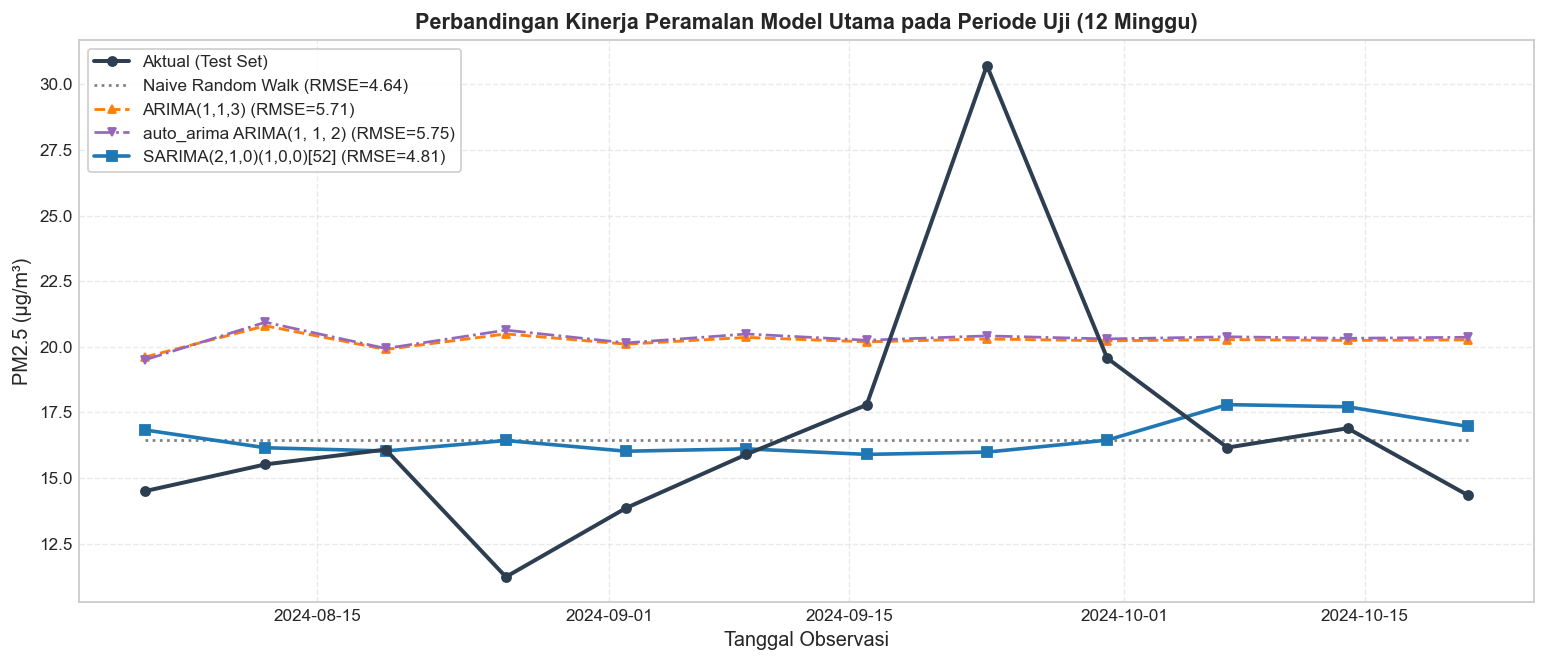

Grafik komparasi tersimpan di: D:\SEMESTER5\adt-project\outputs\figures\fig_tahap5_6_test_forecasts.png


In [15]:
# ==============================================================================
# 7.2 VISUALISASI RAMALAN DATA UJI: AKTUAL VS MODEL UTAMA
# ==============================================================================
fig, ax = plt.subplots(figsize=(12, 5.2))

# Data Aktual
ax.plot(test.index, test.values, color=COLORS["dark"], marker="o", linewidth=2.2, markersize=5, label="Aktual (Test Set)", zorder=10)

# Naive
ax.plot(test.index, naive_pred, color=COLORS["gray"], linestyle=":", linewidth=1.5, label=f"Naive Random Walk (RMSE={naive_metrics['RMSE']:.2f})")

# ARIMA Manual Terbaik
ax.plot(test.index, best_arima_obj["pred"], color=COLORS["secondary"], marker="^", markersize=4, linestyle="--", linewidth=1.6, label=f"{best_arima_obj['Model']} (RMSE={best_arima_obj['RMSE']:.2f})")

# auto_arima
ax.plot(test.index, auto_pred, color=COLORS["purple"], marker="v", markersize=4, linestyle="-.", linewidth=1.5, label=f"auto_arima ARIMA{auto_order} (RMSE={auto_metrics['RMSE']:.2f})")

# SARIMA Terbaik
ax.plot(test.index, best_sarima_obj["pred"], color=COLORS["primary"], marker="s", markersize=5, linestyle="-", linewidth=2.0, label=f"{best_sarima_obj['Model']} (RMSE={best_sarima_obj['RMSE']:.2f})")

ax.set_title("Perbandingan Kinerja Peramalan Model Utama pada Periode Uji (12 Minggu)", fontweight="bold")
ax.set_xlabel("Tanggal Observasi")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)

fig.tight_layout()
fig_comp_path = FIG_DIR / "fig_tahap5_6_test_forecasts.png"
fig.savefig(fig_comp_path, bbox_inches="tight")
plt.show()

print(f"Grafik komparasi tersimpan di: {fig_comp_path}")


PERAMALAN 12 MINGGU KE DEPAN: SARIMA(2,1,0)(1,0,0)[52]


,Minggu,Ramalan,Bawah_80%,Atas_80%,Bawah_95%,Atas_95%
0,2024-10-28,14.77,8.02,21.52,4.45,25.09
1,2024-11-04,14.67,6.50,22.84,2.17,27.17
2,2024-11-11,14.26,5.17,23.36,0.35,28.18
3,2024-11-18,14.35,4.16,24.55,-1.24,29.94
4,2024-11-25,14.41,3.25,25.56,-2.65,31.47
5,2024-12-02,14.35,2.35,26.35,-4.00,32.71
6,2024-12-09,14.19,1.38,27.00,-5.40,33.78
7,2024-12-16,14.14,0.57,27.71,-6.62,34.90
8,2024-12-23,15.01,0.72,29.30,-6.84,36.86
9,2024-12-30,15.13,0.16,30.11,-7.76,38.03


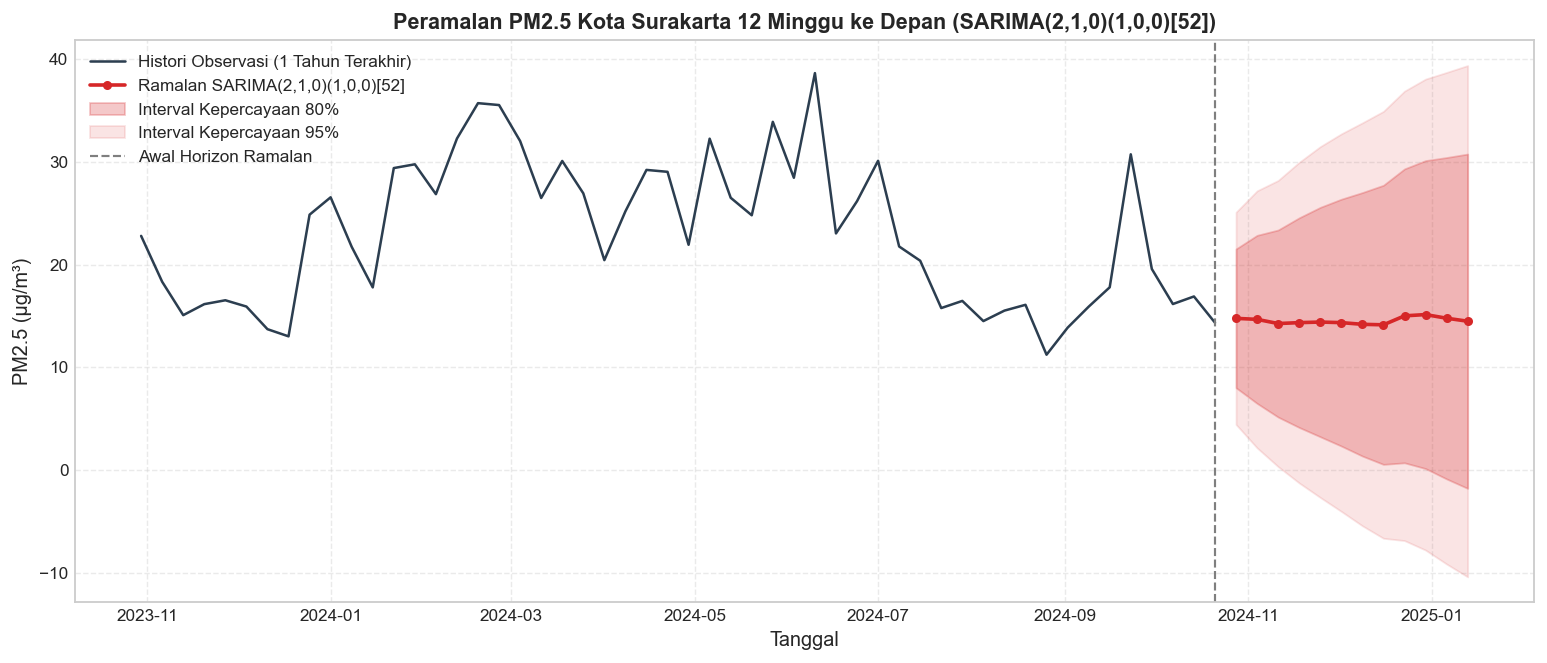

Grafik peramalan ke depan tersimpan di: D:\SEMESTER5\adt-project\outputs\figures\fig_tahap6_future_forecast.png


In [16]:
# ==============================================================================
# 7.3 PERAMALAN 12 MINGGU KE DEPAN DENGAN INTERVAL KEPERCAYAAN 80% & 95%
# ==============================================================================
# Fitting model final pada seluruh data (116 minggu)
final_model = SARIMAX(
    series,
    order=best_sarima_obj["Order"],
    seasonal_order=best_sarima_obj["Seasonal_Order"],
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

HORIZON = 12
forecast_res = final_model.get_forecast(HORIZON)
forecast_mean = forecast_res.predicted_mean
ci_80 = forecast_res.conf_int(alpha=0.20)
ci_95 = forecast_res.conf_int(alpha=0.05)

future_dates = pd.date_range(series.index[-1] + pd.Timedelta(days=7), periods=HORIZON, freq="7D")

df_future_forecast = pd.DataFrame({
    "Minggu": future_dates,
    "Ramalan": forecast_mean.values,
    "Bawah_80%": ci_80.iloc[:, 0].values,
    "Atas_80%": ci_80.iloc[:, 1].values,
    "Bawah_95%": ci_95.iloc[:, 0].values,
    "Atas_95%": ci_95.iloc[:, 1].values,
})

print("=" * 80)
print(f"PERAMALAN 12 MINGGU KE DEPAN: {best_sarima_obj['Model']}")
print("=" * 80)
display(df_future_forecast.round(2))

# Plot Peramalan ke Depan
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.plot(series.index[-52:], series.values[-52:], color=COLORS["dark"], linewidth=1.4, label="Histori Observasi (1 Tahun Terakhir)")
ax.plot(df_future_forecast["Minggu"], df_future_forecast["Ramalan"], color=COLORS["danger"], marker="o", markersize=4, linewidth=2.0, label=f"Ramalan {best_sarima_obj['Model']}")

ax.fill_between(
    df_future_forecast["Minggu"], df_future_forecast["Bawah_80%"], df_future_forecast["Atas_80%"],
    color=COLORS["danger"], alpha=0.25, label="Interval Kepercayaan 80%"
)
ax.fill_between(
    df_future_forecast["Minggu"], df_future_forecast["Bawah_95%"], df_future_forecast["Atas_95%"],
    color=COLORS["danger"], alpha=0.12, label="Interval Kepercayaan 95%"
)

ax.axvline(series.index[-1], color=COLORS["gray"], linestyle="--", linewidth=1.2, label="Awal Horizon Ramalan")
ax.set_title(f"Peramalan PM2.5 Kota Surakarta 12 Minggu ke Depan ({best_sarima_obj['Model']})", fontweight="bold")
ax.set_xlabel("Tanggal")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend(loc="upper left")

fig.tight_layout()
fig_fore_path = FIG_DIR / "fig_tahap6_future_forecast.png"
fig.savefig(fig_fore_path, bbox_inches="tight")
plt.show()

print(f"Grafik peramalan ke depan tersimpan di: {fig_fore_path}")


In [17]:
# ==============================================================================
# 8. EKSPOR TABEL HASIL ANALISIS KE FOLDER OUTPUT
# ==============================================================================
tab_arima_path = TAB_DIR / "tahap5_arima_comparison.csv"
tab_sarima_path = TAB_DIR / "tahap6_sarima_comparison.csv"
tab_future_path = TAB_DIR / "tahap6_forecast_12_weeks.csv"

df_arima_manual.to_csv(tab_arima_path, index=False)
df_sarima.to_csv(tab_sarima_path, index=False)
df_future_forecast.to_csv(tab_future_path, index=False)

print(f"Berhasil mengekspor tabel perbandingan ARIMA ke : {tab_arima_path}")
print(f"Berhasil mengekspor tabel perbandingan SARIMA ke: {tab_sarima_path}")
print(f"Berhasil mengekspor tabel peramalan 12 minggu ke: {tab_future_path}")


Berhasil mengekspor tabel perbandingan ARIMA ke : D:\SEMESTER5\adt-project\outputs\tables\tahap5_arima_comparison.csv
Berhasil mengekspor tabel perbandingan SARIMA ke: D:\SEMESTER5\adt-project\outputs\tables\tahap6_sarima_comparison.csv
Berhasil mengekspor tabel peramalan 12 minggu ke: D:\SEMESTER5\adt-project\outputs\tables\tahap6_forecast_12_weeks.csv


---

## 9. Kesimpulan Akhir & Sintesis Rekomendasi (Tahap 5 & 6)

### 1. Ringkasan Eksekutif Temuan Tahap 5 (ARIMA):
* Dari hasil pengujian differencing Tahap 2B ($d=1$) dan autokorelasi Tahap 4 ($p \in \{1,2,3\}, q \in \{1,2,3\}$), model **ARIMA(1,1,3)** ditetapkan sebagai kandidat manual non-musiman terbaik dengan kriteria penalitas $\text{AICc} = 680,27$ dan residual white noise yang sangat baik ($LB_{20} = 0,8711$).
* Pengujian otomatis melalui `auto_arima` menghasilkan model alternatif yang dikritisi secara tajam: prosedur *stepwise greedy* mengorbankan evaluasi ruang parameter global dan tidak mengevaluasi kelayakan asumsi residual white noise maupun generalisasi out-of-sample.

### 2. Ringkasan Eksekutif Temuan Tahap 6 (SARIMA):
* Komponen musiman $(P,D,Q)_{52}$ diidentifikasi dari lag musiman $m=52$. Karena diferensiasi musiman $D=1$ terbukti memicu *over-differencing* dan membuang 50% data, struktur yang diuji adalah SARIMA($p,1,q$)($P,0,Q$)$_{52}$.
* Model **SARIMA(2,1,0)(1,0,0)[52]** mencapai $\text{AICc} = 310,63$ dan menghasilkan akurasi data uji terbaik di kelas model deret waktu ($\text{RMSE} = 4,814\ \mu\text{g/m}^3$).
* **Justifikasi Kritis:** Meskipun diterapkan, model SARIMA memiliki keterbatasan fundamental: parameter musiman `ar.S.L52` **tidak signifikan secara statistik ($p = 0,4088$)**, seri hanya mencakup 2 siklus musiman penuh (jauh di bawah rekomendasi literatur 3–4 siklus), dan uji Diebold-Mariano membuktikan peramalannya **tidak berbeda signifikan secara statistik dari naive random walk ($p = 0,1965$)**.

### 3. Rekomendasi untuk Analisis Lanjutan:
* **Pengembangan Model GARCH:** Mengingat residual terbukti heteroskedastik (ARCH LM $p < 0,05$), pemodelan volatilitas ARCH/GARCH pada residual SARIMA dapat memperbaiki kalibrasi interval kepercayaan ramalan.
* **Pendekatan Regresi Fourier:** Untuk menangani musiman mingguan panjang ($m=52$) pada sampel pendek tanpa kehilangan derajat bebas yang besar, regresi deret Fourier dengan galat ARIMA (sebagaimana dieksplorasi sebagai bonus pada `analysis.py`) merupakan alternatif parametrik yang sangat menjanjikan.
